# 04 —  Temporal analysis

Use all four processed datasets; run top to bottom after notebooks 00 → 01. No input settings or external helpers.

Crop names/seasons stay separate; climate uses calendar months, not guessed crop seasons. Geography is static.

Read the calculation cells first: group rows, calculate totals/means, and check counts. Chart formatting and file saving can be read afterward.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
# Find the project folder, starting from the notebook's current folder.
for folder in [current, *current.parents]:
    if (folder / "data/processed").is_dir() and (folder / "notebooks").is_dir():
        project_root = folder
        break
else:
    raise FileNotFoundError("Start this notebook inside the project folder.")
os.environ["MPLCONFIGDIR"] = str(project_root / ".cache/matplotlib")
import matplotlib.pyplot as plt

processed_dir = project_root / "data/processed"

output_dir = processed_dir / "eda/temporal_all_datasets"
output_dir.mkdir(parents=True, exist_ok=True)

Read all processed records.

In [2]:
crop_df = pd.read_csv(processed_dir / "crop_yield.csv")
rain_df = pd.read_csv(processed_dir / "precipitation.csv")
vegetation_df = pd.read_csv(processed_dir / "vegetation.csv")
geography_df = pd.read_csv(processed_dir / "geography.csv")

Check dataset coverage and observation keys; district exclusions were already recorded by notebook 01.

In [3]:
datasets = {"Crop yield": crop_df, "Rainfall": rain_df,
            "Vegetation": vegetation_df, "Geography": geography_df}
summary_rows = []
for name, frame in datasets.items():
    district_count = len(frame[["state", "district"]].drop_duplicates())
    summary_rows.append({"dataset": name, "rows": len(frame),
                         "states": frame["state"].nunique(), "districts": district_count})
source_summary = pd.DataFrame(summary_rows)
display(source_summary)
assert not crop_df.duplicated(["state", "district", "year", "crop_name", "season"]).any()
assert not rain_df.duplicated(["state", "district", "Date"]).any()
assert not vegetation_df.duplicated(["state", "district", "date"]).any()

,dataset,rows,states,districts
0,Crop yield,286784,26,399
1,Rainfall,1490016,26,408
2,Vegetation,127725,26,513
3,Geography,784562,35,594


Calculate yield from valid tonnes and hectares; drop the 'Total' season (it repeats other seasons) and crops not measured in tonnes.

In [4]:
year_parts = crop_df["year"].str.extract(r"^(\d{4})-(\d{4})$").apply(pd.to_numeric, errors="coerce")
crop_df["crop_year"] = year_parts[0]
valid_year = year_parts[1] == year_parts[0] + 1
valid_numbers = np.isfinite(crop_df["area"]) & np.isfinite(crop_df["production"])
valid_amounts = (crop_df["area"] > 0) & (crop_df["production"] >= 0)
valid_units = (crop_df["area_unit"] == "Hectare") & (crop_df["production_unit"] == "Tonnes")
non_tonne_crops = ["Coconut", "Cotton(Lint)", "Kapas", "Jute", "Mesta", "Jute & Mesta", "Sannhamp"]
valid_season = crop_df["season"] != "Total"  # "Total" repeats the sum of the other seasons
valid_crop = (valid_year & valid_numbers & valid_amounts & valid_units & valid_season
              & ~crop_df["crop_name"].isin(non_tonne_crops))
print("Crop rows excluded from yield calculations:", int((~valid_crop).sum()))
crop_df = crop_df.loc[valid_crop].copy()
crop_df["crop_year"] = crop_df["crop_year"].astype(int)
crop_df["yield_t_ha"] = crop_df["production"] / crop_df["area"]
# Keep crop names and seasons separate; a shared crop_code is not enough to merge them.

Crop rows excluded from yield calculations: 43290


Summarize every state, crop, season and crop year without combining categories.

In [5]:
crop_state_year = crop_df.groupby(["state", "crop_name", "season", "crop_year"], as_index=False).agg(
    area_ha=("area", "sum"), production_t=("production", "sum"), districts=("district", "nunique")
)
crop_state_year["yield_t_ha"] = crop_state_year["production_t"] / crop_state_year["area_ha"]
crop_trends = crop_state_year.groupby(["crop_name", "season", "crop_year"], as_index=False).agg(
    area_ha=("area_ha", "sum"), production_t=("production_t", "sum"), districts=("districts", "sum")
)
crop_trends["yield_t_ha"] = crop_trends["production_t"] / crop_trends["area_ha"]
display(crop_state_year.head(10))

,state,crop_name,season,crop_year,area_ha,production_t,districts,yield_t_ha
0,Andhra Pradesh,Arecanut,Kharif,2012,23.0,63.0,2,2.739130
1,Andhra Pradesh,Arecanut,Kharif,2013,23.0,69.0,1,3.000000
2,Andhra Pradesh,Arecanut,Kharif,2014,20.0,59.0,1,2.950000
3,Andhra Pradesh,Arecanut,Kharif,2015,20.0,63.0,1,3.150000
4,Andhra Pradesh,Arecanut,Kharif,2016,45.0,149.0,3,3.311111
5,Andhra Pradesh,Arecanut,Kharif,2017,126.0,409.0,3,3.246032
6,Andhra Pradesh,Arecanut,Kharif,2018,137.0,275.0,2,2.007299
7,Andhra Pradesh,Arecanut,Kharif,2019,196.0,928.0,2,4.734694
8,Andhra Pradesh,Arecanut,Kharif,2020,224.0,391.0,3,1.745536
9,Andhra Pradesh,Arecanut,Kharif,2021,275.0,832.0,4,3.025455


Plot the four largest crop/season groups by area; the dashed line shows how many districts report each year. Every group remains in the exported table.

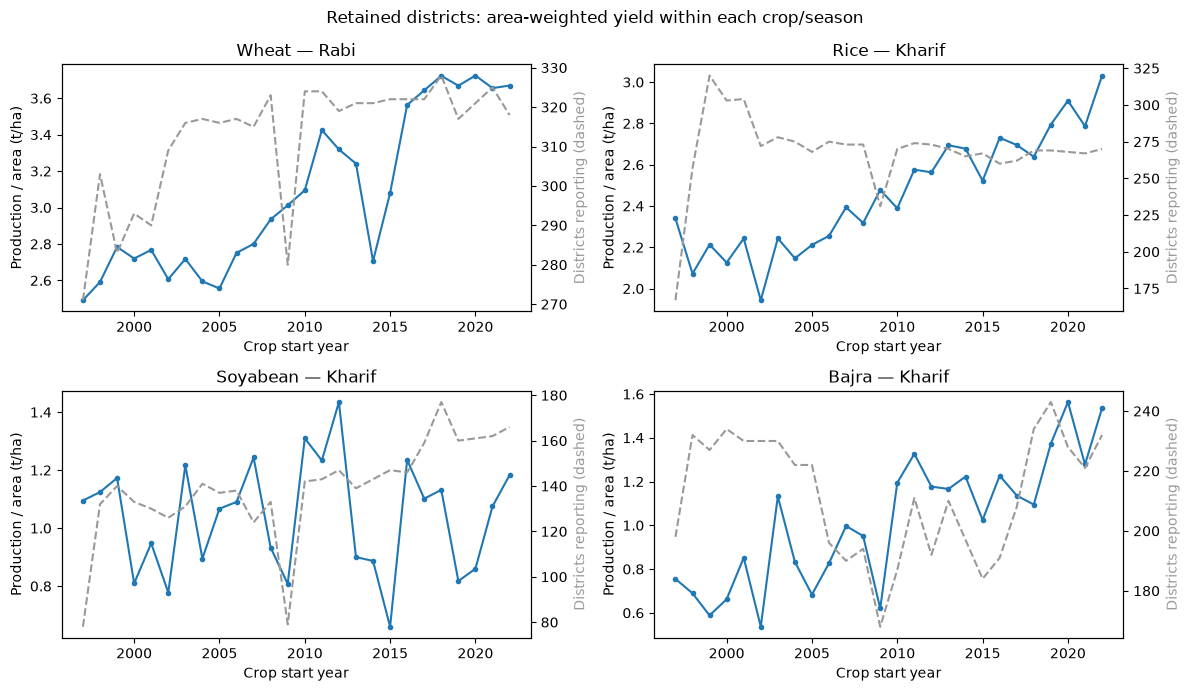

In [6]:
top_groups = crop_df.groupby(["crop_name", "season"])["area"].sum().nlargest(4).index
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (crop, season) in zip(axes.flat, top_groups):
    trend = crop_trends.loc[(crop_trends["crop_name"] == crop) & (crop_trends["season"] == season)]
    trend = trend.set_index("crop_year").reindex(range(crop_df["crop_year"].min(), crop_df["crop_year"].max() + 1))
    ax.plot(trend.index, trend["yield_t_ha"], marker=".")
    ax.set(title=f"{crop} — {season}", xlabel="Crop start year", ylabel="Production / area (t/ha)")
    districts_ax = ax.twinx()
    districts_ax.plot(trend.index, trend["districts"], color="0.6", linestyle="--")
    districts_ax.set_ylabel("Districts reporting (dashed)", color="0.6")
fig.suptitle("Retained districts: area-weighted yield within each crop/season")
fig.tight_layout()
fig.savefig(output_dir / "01_crop_trends.png", dpi=150)
plt.show()

Sum daily rainfall by district/month; keep incomplete monthly totals missing.

In [7]:
rain_df["date"] = pd.to_datetime(rain_df["Date"], errors="coerce")
rain_df["rain_mm"] = pd.to_numeric(rain_df["Precipitation_mm"], errors="coerce")
invalid_rain = ~np.isfinite(rain_df["rain_mm"]) | (rain_df["rain_mm"] < 0)
rain_df.loc[invalid_rain, "rain_mm"] = np.nan
print("Unusable rain dates:", rain_df["date"].isna().sum(), "Missing rain values:", rain_df["rain_mm"].isna().sum())
rain_df = rain_df.dropna(subset=["date"]).copy()
assert not rain_df.duplicated(["state", "district", "date"]).any()

rain_df["month"] = rain_df["date"].dt.to_period("M").dt.to_timestamp()
rain_monthly = rain_df.groupby(["state", "district", "month"], as_index=False).agg(
    observed_days=("rain_mm", "count"), observed_rain_mm=("rain_mm", lambda values: values.sum(min_count=1))
)
rain_monthly["expected_days"] = rain_monthly["month"].dt.days_in_month
complete_month = rain_monthly["observed_days"] == rain_monthly["expected_days"]
rain_monthly["rain_mm"] = rain_monthly["observed_rain_mm"]
rain_monthly.loc[~complete_month, "rain_mm"] = np.nan
display(rain_monthly.head())

Unusable rain dates: 0 Missing rain values: 0


,state,district,month,observed_days,observed_rain_mm,expected_days,rain_mm
0,Andhra Pradesh,Anantapur,2016-06-01,30,57.98,30,57.98
1,Andhra Pradesh,Anantapur,2016-07-01,31,37.28,31,37.28
2,Andhra Pradesh,Anantapur,2016-08-01,31,40.20,31,40.20
3,Andhra Pradesh,Anantapur,2016-09-01,30,71.59,30,71.59
4,Andhra Pradesh,Anantapur,2016-10-01,31,36.11,31,36.11


Compare monthly rainfall across every retained state; state means give each complete district equal weight.

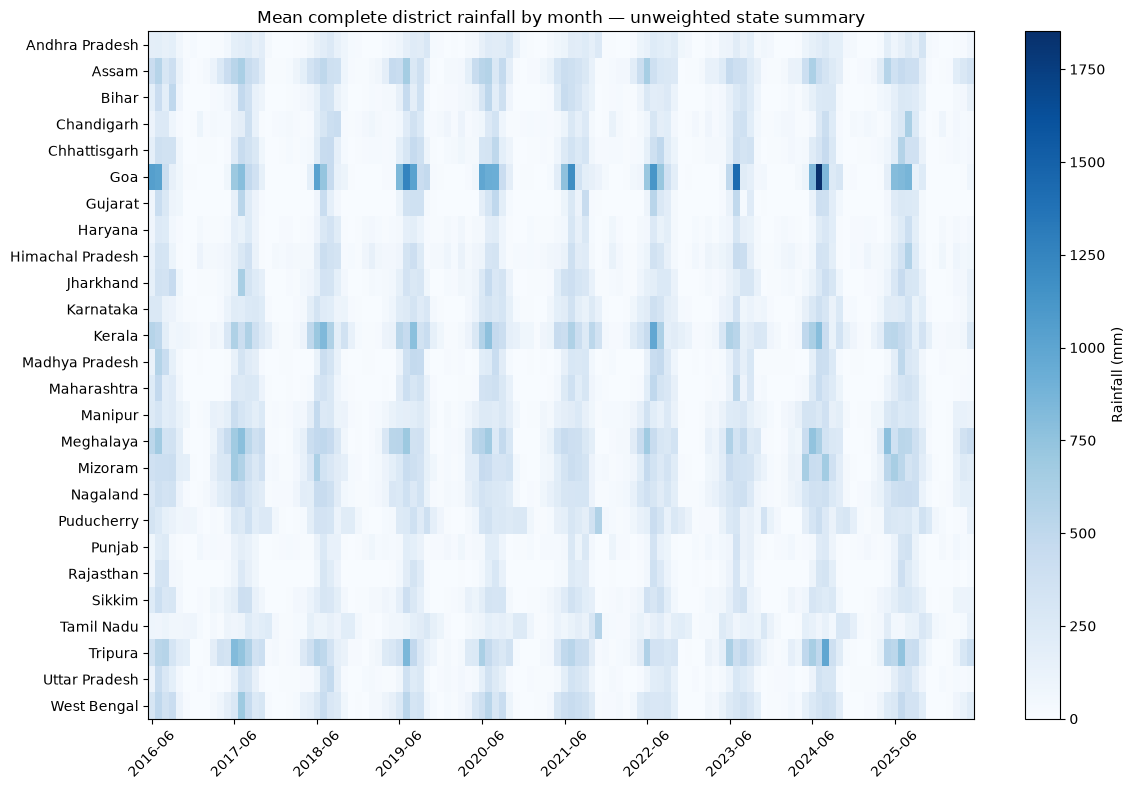

In [8]:
rain_state_month = rain_monthly.groupby(["state", "month"], as_index=False).agg(
    rain_mm=("rain_mm", "mean"), complete_districts=("rain_mm", "count"), districts=("district", "nunique")
)
rain_matrix = rain_state_month.pivot(index="state", columns="month", values="rain_mm")
fig, ax = plt.subplots(figsize=(12, 8))
plot = ax.imshow(rain_matrix, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(rain_matrix)), rain_matrix.index)
ax.set_xticks(range(0, len(rain_matrix.columns), 12), rain_matrix.columns[::12].strftime("%Y-%m"), rotation=45)
ax.set_title("Mean complete district rainfall by month — unweighted state summary")
fig.colorbar(plot, ax=ax, label="Rainfall (mm)")
fig.tight_layout()
fig.savefig(output_dir / "02_monthly_rainfall.png", dpi=150)
plt.show()

Keep source-approved vegetation values; missing pixels, missing images and rejected quality stay missing.

In [9]:
vegetation_df["date"] = pd.to_datetime(vegetation_df["date"], errors="coerce")
vegetation_df["period_end"] = pd.to_datetime(vegetation_df["period_end"], errors="coerce")
approved_by_source = vegetation_df["quality_status"] == "valid"
valid_ndvi = vegetation_df["ndvi_mean"].between(-1, 1)
valid_fraction = vegetation_df["valid_crop_fraction"].between(0, 1)
valid_interval = vegetation_df["period_end"] > vegetation_df["date"]
usable = approved_by_source & valid_ndvi & valid_fraction & valid_interval
vegetation_df["ndvi_used"] = vegetation_df["ndvi_mean"].where(usable)
vegetation_df["evi_used"] = vegetation_df["evi_mean"].where(usable & np.isfinite(vegetation_df["evi_mean"]))
# Use the source's valid flag; do not add the old 0.6 fraction or five-composite gate.
# These are available-observation means, not complete-period/model-ready features.

Explain missing NDVI before averaging; lag/change columns also depend on earlier valid observations.

In [10]:
ndvi_quality = vegetation_df.groupby("quality_status", dropna=False).agg(
    records=("ndvi_mean", "size"), published_ndvi=("ndvi_mean", "count"),
    raw_ndvi=("raw_ndvi_mean", "count"), usable_ndvi=("ndvi_used", "count")
).reset_index()
ndvi_quality["missing_published_ndvi"] = ndvi_quality["records"] - ndvi_quality["published_ndvi"]
ndvi_columns = [column for column in vegetation_df if "ndvi" in column and column != "ndvi_used"]
ndvi_missing = vegetation_df[ndvi_columns].isna().sum().rename("missing_rows").to_frame()
display(ndvi_quality)
display(ndvi_missing)
# Raw NDVI can exist when quality fails; it must not replace missing approved NDVI.

,quality_status,records,published_ndvi,raw_ndvi,usable_ndvi,missing_published_ndvi
0,low_valid_crop_fraction,40464,0,40464,0,40464
1,missing_source_image,1026,0,0,0,1026
2,no_mapped_cropland,1528,0,0,0,1528
3,no_valid_pixels,11874,0,0,0,11874
4,valid,72833,72833,72833,72833,0


,missing_rows
ndvi_mean,54892
raw_ndvi_mean,14428
ndvi_lag_1period,55387
ndvi_change,71966
ndvi_slope_per_day,71966


Average available composites by start month and always keep their usable counts; one composite is not full-month coverage.

In [11]:
vegetation_df["month"] = vegetation_df["date"].dt.to_period("M").dt.to_timestamp()
vegetation_monthly = vegetation_df.groupby(["state", "district", "month"], as_index=False).agg(
    observed_composites=("date", "size"), usable_composites=("ndvi_used", "count"),
    ndvi_mean=("ndvi_used", "mean"), evi_mean=("evi_used", "mean")
)
vegetation_monthly["usable_share"] = vegetation_monthly["usable_composites"] / vegetation_monthly["observed_composites"]
vegetation_state_month = vegetation_monthly.groupby(["state", "month"], as_index=False).agg(
    ndvi_mean=("ndvi_mean", "mean"), observed_composites=("observed_composites", "sum"),
    usable_composites=("usable_composites", "sum"), districts_with_ndvi=("ndvi_mean", "count")
)
vegetation_state_month["usable_share"] = vegetation_state_month["usable_composites"] / vegetation_state_month["observed_composites"]
display(vegetation_monthly.head())

,state,district,month,observed_composites,usable_composites,ndvi_mean,evi_mean,usable_share
0,Andhra Pradesh,Adilabad,2016-01-01,2,2,0.384556,0.223390,1.0
1,Andhra Pradesh,Adilabad,2016-02-01,2,2,0.325197,0.192956,1.0
2,Andhra Pradesh,Adilabad,2016-03-01,2,2,0.314816,0.181807,1.0
3,Andhra Pradesh,Adilabad,2016-04-01,2,2,0.273982,0.167113,1.0
4,Andhra Pradesh,Adilabad,2016-05-01,2,2,0.245763,0.143465,1.0


Read the NDVI pattern beside its usable-data share; blank cells mean no usable value.

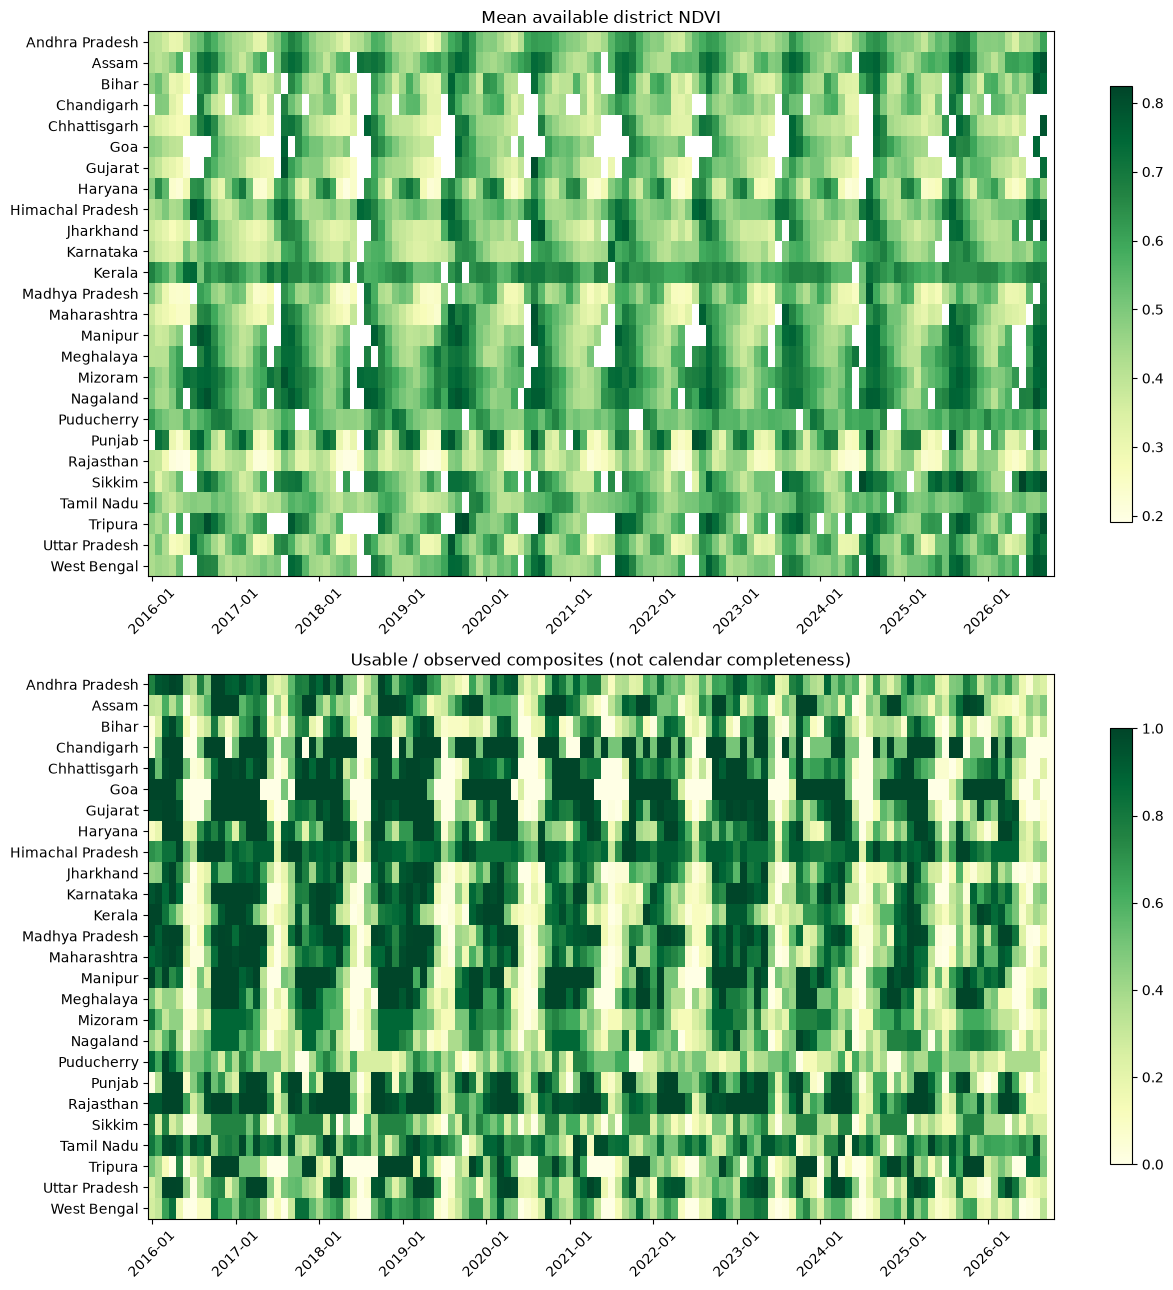

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(13, 13))
for ax, column, title in zip(axes, ["ndvi_mean", "usable_share"],
    ["Mean available district NDVI", "Usable / observed composites (not calendar completeness)"]):
    matrix = vegetation_state_month.pivot(index="state", columns="month", values=column)
    plot = ax.imshow(matrix, aspect="auto", cmap="YlGn")
    ax.set_yticks(range(len(matrix)), matrix.index)
    ax.set_xticks(range(0, len(matrix.columns), 12), matrix.columns[::12].strftime("%Y-%m"), rotation=45)
    ax.set_title(title)
    fig.colorbar(plot, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(output_dir / "03_monthly_ndvi_and_coverage.png", dpi=150)
plt.show()

Join monthly climate summaries on state/district/month to expose overlap; this is not a crop-season yield join.

In [13]:
climate_monthly = rain_monthly.merge(vegetation_monthly, on=["state", "district", "month"],
    how="outer", validate="one_to_one", indicator="source_match")
climate_monthly["usable_pair"] = climate_monthly["rain_mm"].notna() & climate_monthly["ndvi_mean"].notna()
climate_overlap = climate_monthly.groupby("state", as_index=False).agg(
    district_months=("month", "size"), rain_months=("rain_mm", "count"),
    ndvi_months=("ndvi_mean", "count"), usable_pairs=("usable_pair", "sum")
)
display(climate_overlap)

,state,district_months,rain_months,ndvi_months,usable_pairs
0,Andhra Pradesh,2990,1560,2165,1143
1,Assam,2990,1560,2105,1096
2,Bihar,4810,4080,2585,2177
3,Chandigarh,130,120,103,98
4,Chhattisgarh,2080,840,1463,593
5,Goa,260,240,173,162
6,Gujarat,3250,2040,2247,1437
7,Haryana,2470,2040,1899,1594
8,Himachal Pradesh,1560,1440,1367,1287
9,Jharkhand,2860,2400,1788,1526


Save all groups and quality counts; static geography coverage is included in source_summary.

In [14]:
assert vegetation_monthly.loc[vegetation_monthly["usable_composites"] == 0, "ndvi_mean"].isna().all()
assert not climate_monthly.duplicated(["state", "district", "month"]).any()
tables_to_save = {"source_summary": source_summary, "crop_state_year": crop_state_year,
    "crop_trends": crop_trends, "rain_district_month": rain_monthly, "rain_state_month": rain_state_month,
    "vegetation_district_month": vegetation_monthly, "vegetation_state_month": vegetation_state_month,
    "ndvi_quality": ndvi_quality, "ndvi_missing_columns": ndvi_missing.reset_index(names="column"),
    "climate_monthly": climate_monthly, "climate_overlap": climate_overlap}
for name, frame in tables_to_save.items():
    frame.to_csv(output_dir / f"{name}.csv", index=False)
print("Saved all-dataset temporal outputs:", output_dir.relative_to(project_root))

Saved all-dataset temporal outputs: data/processed/eda/temporal_all_datasets


## Findings (all retained districts, crop years 1997–2022)

Snapshot of the current outputs; recheck these numbers if the processed inputs change. Trends describe retained districts, not complete national coverage.

- Wheat (Rabi) yield rose from 2.49 to 3.67 t/ha (1997→2022), rice (Kharif) from 2.34 to 3.03 and bajra (Kharif) from 0.76 to 1.54. Soyabean (Kharif) is volatile with no clear trend (1.10→1.18).
- 2002 is a low year for all three Kharif crops shown, consistent with that year's monsoon drought. The 2009 dips coincide with a drop in reporting districts, so coverage and weather cannot be separated there.
- Reporting districts change by year (rice: 167–320; wheat: 271–328), so part of each trend line reflects coverage rather than real change.
- Mean district rainfall peaks in July (348 mm) and is lowest in February (12 mm).
- Mean available NDVI is lowest in April–May (0.35) and highest in August (0.64).
- Monsoon NDVI is sparse: only 13% (July) and 27% (August) of composites are usable, versus 83% in April, so the monsoon NDVI pattern is indicative only.
- 34,268 of 66,690 district-months have both complete rainfall and usable NDVI.